In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import dantistUtils as du
import colorpalette as cp

# ==============================================================================
# 1. ИСПОЛЬЗОВАНИЕ АЛГОРИТМА ИЗ dantistUtils ДЛЯ АНАЛИЗА ПОРАЖЕНИЙ (ТОЛЬКО R КАНАЛ)
# ==============================================================================

def get_teeth_mask_from_contours(image_rgb):
    """
    Использует функцию find_conturs из dantistUtils для получения маски зубов
    """
    img_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
    img_with_contours, gray_mask, contours, hierarchy = du.find_conturs(img_bgr)
    
    teeth_mask = np.zeros(img_bgr.shape[:2], dtype=np.uint8)
    cv2.drawContours(teeth_mask, contours, -1, 255, -1)
    
    from skimage import morphology
    from scipy import ndimage
    
    teeth_mask_bool = teeth_mask.astype(bool)
    teeth_mask_cleaned = morphology.remove_small_objects(teeth_mask_bool, min_size=500)
    teeth_mask_filled = ndimage.binary_fill_holes(teeth_mask_cleaned).astype(np.uint8) * 255
    
    return teeth_mask_filled, contours

def analyze_with_dantistUtils_R_only(image_rgb, teeth_mask):
    """
    Использует алгоритм анализа из dantistUtils (tooth_Analise)
    Рассчитывает дельты ТОЛЬКО по R (красному) каналу
    """
    # Конвертируем в BGR для dantistUtils
    img_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
    
    # Получаем контуры из маски
    contours, _ = cv2.findContours(teeth_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Цветовая палитра для визуализации (из colorpalette)
    colors = cp.firecolorpalette
    
    # Вызываем функцию анализа из dantistUtils
    result_img, q0, q1, q2, q3, q4, mean_deltaR, \
    changing_ratio_red_green, max_changing_ratio_red_green, \
    mean_deltaF, avg_fluorescence_loss, max_fluorescence_loss = du.tooth_Analise(img_bgr, contours, colors)
    
    # Конвертируем результат обратно в RGB
    result_img_rgb = cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB)
    
    # Создаем карту ДЕЛЬТ ТОЛЬКО ПО R КАНАЛУ для визуализации
    delta_r_map = np.zeros(teeth_mask.shape, dtype=np.float32)
    
    img_bgr_copy = img_bgr.copy()
    img_masked = cv2.bitwise_and(img_bgr_copy, img_bgr_copy, mask=teeth_mask)
    
    # Вычисляем средние значения цветов для здоровой ткани
    mean_B, mean_G, mean_R = du.mean_colors(img_masked)
    
    # Создаем карту дельт только по R каналу
    rows, cols = np.where(teeth_mask > 0)
    for idx in range(len(rows)):
        j, i = rows[idx], cols[idx]
        color = img_bgr[j, i]
        
        if np.any(color != 0):
            # Только R канал (красный)
            deltaR = max(0, mean_R - color[2])
            delta_r_map[j, i] = deltaR
    
    return result_img_rgb, delta_r_map, {
        'q0': q0, 'q1': q1, 'q2': q2, 'q3': q3, 'q4': q4,
        'mean_deltaR': mean_deltaR,
        'changing_ratio_red_green': changing_ratio_red_green,
        'max_changing_ratio_red_green': max_changing_ratio_red_green,
        'mean_deltaF': mean_deltaF,
        'avg_fluorescence_loss': avg_fluorescence_loss,
        'max_fluorescence_loss': max_fluorescence_loss
    }

def calculate_lesion_statistics_dantist_R_only(delta_r_map, teeth_mask):
    """
    Рассчитывает статистику поражений на основе карты дельт ТОЛЬКО по R каналу
    Пороги из dantistUtils: 45, 60, 75, 90, 120
    """
    from scipy import ndimage
    from skimage import morphology
    
    # Маска поражений (deltaR > 45)
    lesion_mask_raw = (delta_r_map > 45) & (teeth_mask == 255)
    lesion_mask = morphology.remove_small_objects(lesion_mask_raw, min_size=20).astype(np.uint8)
    
    # Находим связные компоненты
    labeled_lesions, num_lesions = ndimage.label(lesion_mask)
    
    lesion_stats = []
    
    for lesion_id in range(1, num_lesions + 1):
        current_lesion_mask = (labeled_lesions == lesion_id)
        
        if not np.any(current_lesion_mask & (teeth_mask == 255)):
            continue
        
        mean_delta_r = np.mean(delta_r_map[current_lesion_mask])
        area_px = np.sum(current_lesion_mask)
        delta_q = mean_delta_r * area_px
        
        if mean_delta_r < 60:
            severity = "Mild"
        elif mean_delta_r < 75:
            severity = "Moderate"
        elif mean_delta_r < 90:
            severity = "Severe"
        elif mean_delta_r < 120:
            severity = "Critical"
        else:
            severity = "Extreme"
        
        lesion_stats.append({
            'id': lesion_id,
            'Delta R': round(mean_delta_r, 1),
            'Area (px)': area_px,
            'DQ (DeltaR*px)': round(delta_q, 1),
            'Severity': severity
        })
    
    total_area = np.sum(lesion_mask)
    total_lesions = len(lesion_stats)
    total_teeth_pixels = np.sum(teeth_mask == 255)
    
    # Расчет процентного распределения по порогам
    thresholds = [45, 60, 75, 90, 120]
    threshold_counts = {}
    for thr in thresholds:
        count = np.sum((delta_r_map > thr) & (teeth_mask == 255))
        threshold_counts[f'Q{thr}'] = round((count / total_teeth_pixels) * 100, 2) if total_teeth_pixels > 0 else 0
    
    summary_stats = {
        'Total lesions': total_lesions,
        'Mean Delta R': round(np.mean([s['Delta R'] for s in lesion_stats]), 1) if lesion_stats else 0,
        'Total area (px)': total_area,
        'Total DQ': round(np.sum([s['DQ (DeltaR*px)'] for s in lesion_stats]), 1) if lesion_stats else 0,
        'Healthy area (px)': total_teeth_pixels - total_area,
        'Enamel affected (%)': round((total_area / total_teeth_pixels) * 100, 2) if total_teeth_pixels > 0 else 0,
        **threshold_counts
    }
    
    return lesion_stats, summary_stats

# ==============================================================================
# 2. ВИЗУАЛИЗАЦИЯ С ИСПОЛЬЗОВАНИЕМ FIRECOLORPALETTE (УПРОЩЕННАЯ)
# ==============================================================================

def apply_firecolorpalette_to_delta_map(delta_r_map, teeth_mask):
    """
    Применяет firecolorpalette к карте дельт
    """
    fire_colors = cp.firecolorpalette
    
    # Создаем пустую карту для наложения цветов
    color_map = np.zeros((*delta_r_map.shape, 3), dtype=np.uint8)
    
    # Диапазоны Delta R и соответствующие цвета из firecolorpalette
    ranges = [
        (0, 45, (200, 200, 200)),           # Серый - здоровые участки (Delta < 45)
        (45, 60, tuple(reversed(fire_colors[4]))),   # orangered - легкая
        (60, 75, tuple(reversed(fire_colors[3]))),   # darkorange - средняя
        (75, 90, tuple(reversed(fire_colors[2]))),   # orange - тяжелая
        (90, 120, tuple(reversed(fire_colors[1]))),  # gold - критическая
        (120, 256, tuple(reversed(fire_colors[0])))  # yellow - экстремальная
    ]
    
    # Применяем цвета к каждому диапазону
    for low, high, color in ranges:
        range_mask = (delta_r_map >= low) & (delta_r_map < high) & (teeth_mask == 255)
        color_map[range_mask] = color
    
    # Область вне зубов делаем белой
    color_map[teeth_mask == 0] = [255, 255, 255]
    
    return color_map

def create_delta_r_heat_map(teeth_mask, delta_r_map):
    """
    Создает тепловую карту дельт по R каналу (используя hot colormap)
    """
    delta_masked = np.ma.masked_where(teeth_mask == 0, delta_r_map)
    return delta_masked

def create_legend_dantist_R_firecolor():
    """
    Создает легенду с firecolorpalette для порогов dantistUtils
    """
    legend_elements = [
        Patch(facecolor='gray', alpha=0.7, label='DeltaR < 45 (Healthy)'),
        Patch(facecolor='orangered', alpha=0.7, label='DeltaR 45-60 (Mild)'),
        Patch(facecolor='darkorange', alpha=0.7, label='DeltaR 60-75 (Moderate)'),
        Patch(facecolor='orange', alpha=0.7, label='DeltaR 75-90 (Severe)'),
        Patch(facecolor='gold', alpha=0.7, label='DeltaR 90-120 (Critical)'),
        Patch(facecolor='yellow', alpha=0.7, label='DeltaR > 120 (Extreme)')
    ]
    return legend_elements

# ==============================================================================
# 3. ГЛАВНАЯ ФУНКЦИЯ (УПРОЩЕННАЯ ВИЗУАЛИЗАЦИЯ - ТОЛЬКО 3 ИЗОБРАЖЕНИЯ)
# ==============================================================================

def analyze_dental_qlf_dantist_R_only(image_path):
    """
    Главная функция: использует алгоритм из dantistUtils ТОЛЬКО по R каналу
    Визуализация: 1) исходное с контуром, 2) firecolorpalette, 3) тепловая карта
    """
    import warnings
    warnings.filterwarnings('ignore', category=FutureWarning)
    
    # 1. Загрузка изображения
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error: cannot load image from {image_path}")
        return
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    print("="*70)
    print("QLF ANALYSIS - dantistUtils ALGORITHM (RED CHANNEL ONLY)")
    print("="*70)
    
    print("\nStep 1: Tooth segmentation...")
    teeth_mask, contours = get_teeth_mask_from_contours(img_rgb)
    
    if np.sum(teeth_mask == 255) == 0:
        print("Error: no teeth found")
        return
    
    print(f"✓ Segmented {np.sum(teeth_mask == 255)} tooth pixels")
    print(f"✓ Found {len(contours)} contours")
    
    print("\nStep 2: dantistUtils analysis (Delta R only)...")
    result_img, delta_r_map, metrics = analyze_with_dantistUtils_R_only(img_rgb, teeth_mask)
    
    print("✓ Delta R calculation completed")
    
    print("\nStep 3: Lesion detection (threshold Delta R > 45)...")
    lesion_stats, summary_stats = calculate_lesion_statistics_dantist_R_only(delta_r_map, teeth_mask)
    
    print(f"✓ Detected {summary_stats['Total lesions']} lesions")
    print(f"✓ Affected {summary_stats['Enamel affected (%)']}% of enamel")
    
    print("\nStep 4: Creating visualizations...")
    
    # Создаем визуализации
    delta_r_firecolor_map = apply_firecolorpalette_to_delta_map(delta_r_map, teeth_mask)
    delta_r_heat_map = create_delta_r_heat_map(teeth_mask, delta_r_map)
    
    # Изображение с контурами (исходное + контуры зубов)
    img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    img_with_contours, _, _, _ = du.find_conturs(img_bgr)
    img_with_contours_rgb = cv2.cvtColor(img_with_contours, cv2.COLOR_BGR2RGB)
    
    # 4. Визуализация 3 изображений
    fig = plt.figure(figsize=(18, 6))
    
    # Изображение 1: Исходное с контурами зубов
    ax1 = plt.subplot(1, 3, 1)
    ax1.imshow(img_with_contours_rgb)
    ax1.set_title("Original Image with Tooth Contours", fontsize=12)
    ax1.axis('off')
    
    # Изображение 2: Карта поражений с firecolorpalette
    ax2 = plt.subplot(1, 3, 2)
    ax2.imshow(delta_r_firecolor_map)
    ax2.set_title("Lesion Map (firecolorpalette)", fontsize=12)
    ax2.axis('off')
    
    # Изображение 3: Тепловая карта дельт по R каналу
    ax3 = plt.subplot(1, 3, 3)
    im = ax3.imshow(delta_r_heat_map, cmap='hot', vmin=0, vmax=150)
    ax3.set_title("Delta R Heat Map", fontsize=12)
    ax3.axis('off')
    plt.colorbar(im, ax=ax3, label='Delta R', fraction=0.046, pad=0.04)
    
    # Добавляем общую легенду под изображениями
    legend_elements = create_legend_dantist_R_firecolor()
    fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.05),
               ncol=3, title="Lesion severity (Delta R with firecolorpalette):", 
               title_fontsize=10, fontsize=8)
    
    plt.tight_layout()
    # plt.subplots_adjust(bottom=0.15)
    plt.savefig('output2.png', dpi=1300, bbox_inches='tight', facecolor='white')
    plt.show()
    
    # 5. Вывод статистики в консоль
    print("\n" + "="*70)
    print("DANTISTUTILS ANALYSIS RESULTS (RED CHANNEL ONLY)")
    print("="*70)
    
    print("\n--- Summary statistics ---")
    for key, value in summary_stats.items():
        print(f"{key}: {value}")
    
    print("\n--- QLF Metrics ---")
    print(f"q0 (DeltaR>45): {metrics['q0']:.4f}")
    print(f"q1 (DeltaR>60): {metrics['q1']:.4f}")
    print(f"q2 (DeltaR>75): {metrics['q2']:.4f}")
    print(f"q3 (DeltaR>90): {metrics['q3']:.4f}")
    print(f"q4 (DeltaR>120): {metrics['q4']:.4f}")
    print(f"mean_deltaR: {metrics['mean_deltaR']:.2f}")
    print(f"mean_deltaF: {metrics['mean_deltaF']:.2f}")
    print(f"changing_ratio_red_green: {metrics['changing_ratio_red_green']:.2f}")
    print(f"avg_fluorescence_loss: {metrics['avg_fluorescence_loss']:.2f}")
    print(f"max_fluorescence_loss: {metrics['max_fluorescence_loss']:.2f}")
    
    if lesion_stats:
        print("\n--- Detailed lesion statistics ---")
        df = pd.DataFrame(lesion_stats)
        print(df.to_string(index=False))
        
        print("\n--- Treatment recommendations ---")
        for lesion in lesion_stats:
            delta_val = lesion['Delta R']
            if delta_val < 60:
                rec = "Remineralization therapy"
            elif delta_val < 75:
                rec = "Infiltration (ICON)"
            elif delta_val < 90:
                rec = "Cavity preparation"
            elif delta_val < 120:
                rec = "Deep preparation"
            else:
                rec = "Critical - dentin involved"
            print(f"Lesion #{lesion['id']} (DeltaR={delta_val}): {rec}")
    else:
        print("\n✓ No lesions detected (Delta R > 45)")
    
    print("\n" + "="*70)
    print("USED MODULES:")
    print("• Segmentation: dantistUtils.find_conturs()")
    print("• Analysis: dantistUtils.tooth_Analise() - RED CHANNEL ONLY")
    print("• Color scheme: colorpalette.firecolorpalette")
    print("• Detection threshold: Delta R > 45")
    print("="*70)
    
    return teeth_mask, lesion_stats, summary_stats, metrics

# ==============================================================================
# 4. ФУНКЦИЯ ДЛЯ ПРОИЗВОЛЬНОГО КОЛИЧЕСТВА ИЗОБРАЖЕНИЙ
# ==============================================================================

def analyze_multiple_images(image_paths):
    """
    Обрабатывает произвольное количество изображений
    """
    num_images = len(image_paths)
    
    print("\n" + "="*80)
    print(f"MULTI-IMAGE ANALYSIS: PROCESSING {num_images} IMAGES")
    print("="*80)
    
    all_results = []
    
    for idx, path in enumerate(image_paths):
        print(f"\n--- Processing image {idx+1}/{num_images}: {path} ---")
        result = analyze_dental_qlf_dantist_R_only(path)
        if result is not None:
            all_results.append(result)
    
    # Сравнительная таблица
    if len(all_results) > 1:
        print("\n" + "="*100)
        print(f"COMPARISON TABLE FOR {len(all_results)} IMAGES")
        print("="*100)
        
        comparison_data = []
        for idx, (teeth_mask, lesion_stats, summary_stats, metrics) in enumerate(all_results):
            comparison_data.append({
                'Image': idx + 1,
                'Lesions': summary_stats['Total lesions'],
                'Mean_DeltaR': summary_stats['Mean Delta R'],
                'Affected(%)': summary_stats['Enamel affected (%)'],
                'Total_Area': summary_stats['Total area (px)'],
                'q0': metrics['q0'],
                'q1': metrics['q1'],
                'q2': metrics['q2'],
                'q3': metrics['q3'],
                'q4': metrics['q4']
            })
        
        df = pd.DataFrame(comparison_data)
        print(df.to_string(index=False))
        
        print("\n" + "-"*100)
        print("SUMMARY STATISTICS:")
        print(f"  Average lesions: {df['Lesions'].mean():.1f}")
        print(f"  Average affected: {df['Affected(%)'].mean():.2f}%")
        print(f"  Max affected: {df['Affected(%)'].max():.2f}%")
        print(f"  Min affected: {df['Affected(%)'].min():.2f}%")
        print("="*100)
    
    return all_results



MULTI-IMAGE ANALYSIS: PROCESSING 1 IMAGES

--- Processing image 1/1: uploads/20260228_113710_mihn.jpg ---
QLF ANALYSIS - dantistUtils ALGORITHM (RED CHANNEL ONLY)

Step 1: Tooth segmentation...
✓ Segmented 276269 tooth pixels
✓ Found 12 contours

Step 2: dantistUtils analysis (Delta R only)...
✓ Delta R calculation completed

Step 3: Lesion detection (threshold Delta R > 45)...
✓ Detected 42 lesions
✓ Affected 12.36% of enamel

Step 4: Creating visualizations...


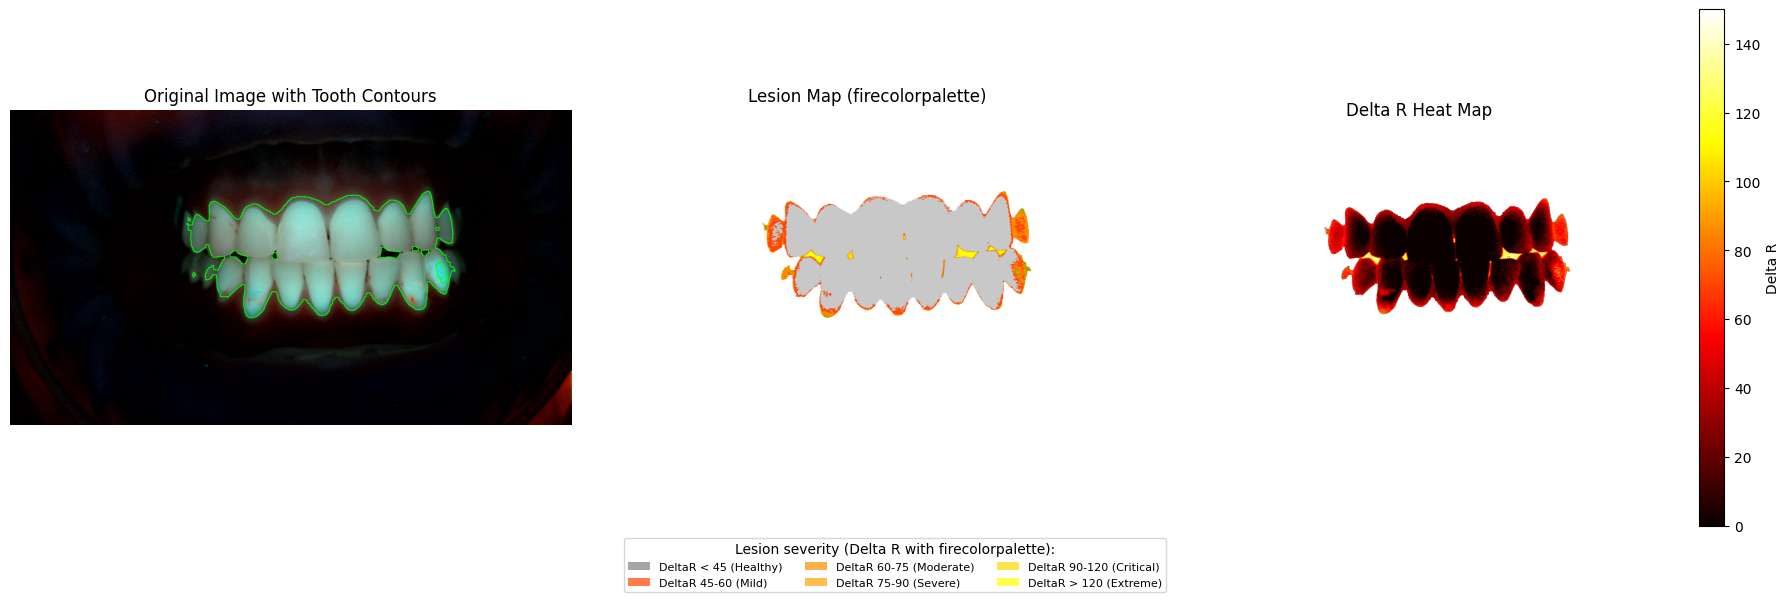


DANTISTUTILS ANALYSIS RESULTS (RED CHANNEL ONLY)

--- Summary statistics ---
Total lesions: 42
Mean Delta R: 56.0
Total area (px): 34142
Total DQ: 2214556.7
Healthy area (px): 242127.0
Enamel affected (%): 12.36
Q45: 12.58
Q60: 5.76
Q75: 1.97
Q90: 1.23
Q120: 0.78

--- QLF Metrics ---
q0 (DeltaR>45): 0.4296
q1 (DeltaR>60): 0.0779
q2 (DeltaR>75): 0.0798
q3 (DeltaR>90): 0.0780
q4 (DeltaR>120): 0.1438
mean_deltaR: 17.58
mean_deltaF: 89.67
changing_ratio_red_green: 0.04
avg_fluorescence_loss: 0.22
max_fluorescence_loss: 0.64

--- Detailed lesion statistics ---
 id    Delta R  Area (px)  DQ (DeltaR*px) Severity
  1  61.799999      12236        755906.4 Moderate
  2  49.299999        463         22805.6     Mild
  3  48.599998        193          9385.5     Mild
  4  47.400002         67          3178.5     Mild
  5  46.799999         49          2293.5     Mild
  6  47.599998         73          3475.5     Mild
  7  47.400002         50          2370.0     Mild
  8  46.299999         34    

In [2]:
# ==============================================================================
# 4. ПРИМЕР ИСПОЛЬЗОВАНИЯ
# ==============================================================================

if __name__ == "__main__":
    image_paths = [
        "uploads/20260228_113710_mihn.jpg",

    ]
    
    analyze_multiple_images(image_paths)

In [3]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import dantistUtils as du
import colorpalette as cp

# ==============================================================================
# 1. Использование существующей сегментации из dantistUtils
# ==============================================================================

def get_teeth_mask_from_contours(image_rgb):
    """
    Использует функцию find_conturs из dantistUtils для получения маски зубов
    """
    img_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
    img_with_contours, gray_mask, contours, hierarchy = du.find_conturs(img_bgr)
    
    teeth_mask = np.zeros(img_bgr.shape[:2], dtype=np.uint8)
    cv2.drawContours(teeth_mask, contours, -1, 255, -1)
    
    from skimage import morphology
    from scipy import ndimage
    
    teeth_mask_bool = teeth_mask.astype(bool)
    teeth_mask_cleaned = morphology.remove_small_objects(teeth_mask_bool, min_size=500)
    teeth_mask_filled = ndimage.binary_fill_holes(teeth_mask_cleaned).astype(np.uint8) * 255
    
    return teeth_mask_filled, contours

# ==============================================================================
# 2. QLF анализ с использованием firecolorpalette
# ==============================================================================

def analyze_qlf_with_firepalette(image_rgb, teeth_mask):
    """
    Анализирует зубы по методике QLF с использованием firecolorpalette
    """
    green_channel = image_rgb[:, :, 1].astype(np.float32)
    tooth_pixels = green_channel[teeth_mask == 255]
    
    if len(tooth_pixels) == 0:
        return None, None, None, None, "Teeth not found."
    
    max_fl_intensity = np.percentile(tooth_pixels, 95)
    if max_fl_intensity < 1e-3:
        max_fl_intensity = 1.0
    
    delta_f_map = np.zeros_like(green_channel)
    teeth_region = (teeth_mask == 255)
    delta_f_map[teeth_region] = (1 - green_channel[teeth_region] / max_fl_intensity) * 100
    delta_f_map = np.clip(delta_f_map, 0, 100)
    
    lesion_mask_raw = (delta_f_map > 10) & teeth_region
    from skimage import morphology
    lesion_mask = morphology.remove_small_objects(lesion_mask_raw, min_size=20).astype(np.uint8)
    
    return delta_f_map, lesion_mask, max_fl_intensity, tooth_pixels, None

def calculate_lesion_statistics(delta_f_map, lesion_mask, teeth_mask):
    """
    Рассчитывает статистику поражений
    """
    from scipy import ndimage
    
    labeled_lesions, num_lesions = ndimage.label(lesion_mask)
    
    lesion_stats = []
    
    for lesion_id in range(1, num_lesions + 1):
        current_lesion_mask = (labeled_lesions == lesion_id)
        
        if not np.any(current_lesion_mask & (teeth_mask == 255)):
            continue
        
        mean_df = np.mean(delta_f_map[current_lesion_mask])
        area_px = np.sum(current_lesion_mask)
        delta_q = mean_df * area_px
        
        if mean_df < 45:
            severity = "Mild"
        elif mean_df < 60:
            severity = "Moderate"
        elif mean_df < 75:
            severity = "Severe"
        elif mean_df < 90:
            severity = "Critical"
        else:
            severity = "Extreme"
        
        lesion_stats.append({
            'id': lesion_id,
            'DF (%)': round(mean_df, 1),
            'Area (px)': area_px,
            'DQ (DF*px)': round(delta_q, 1),
            'Severity': severity
        })
    
    total_area = np.sum(lesion_mask)
    total_lesions = len(lesion_stats)
    total_teeth_pixels = np.sum(teeth_mask == 255)
    
    summary_stats = {
        'Total lesions': total_lesions,
        'Mean DF (%)': round(np.mean([s['DF (%)'] for s in lesion_stats]), 1) if lesion_stats else 0,
        'Total area (px)': total_area,
        'Total DQ': round(np.sum([s['DQ (DF*px)'] for s in lesion_stats]), 1) if lesion_stats else 0,
        'Healthy area (px)': total_teeth_pixels - total_area,
        'Enamel affected (%)': round((total_area / total_teeth_pixels) * 100, 2) if total_teeth_pixels > 0 else 0
    }
    
    return lesion_stats, summary_stats

# ==============================================================================
# 3. Визуализация (упрощенная - без маркировки очагов и маски)
# ==============================================================================

def apply_firecolorpalette_overlay(image_rgb, teeth_mask, lesion_mask, delta_f_map):
    """
    Накладывает firecolorpalette на области поражения
    """
    fire_colors = cp.firecolorpalette
    
    color_overlay = np.zeros_like(image_rgb, dtype=np.float32)
    
    ranges = [
        (10, 45, tuple(reversed(fire_colors[4]))),
        (45, 60, tuple(reversed(fire_colors[3]))),
        (60, 75, tuple(reversed(fire_colors[2]))),
        (75, 90, tuple(reversed(fire_colors[1]))),
        (90, 101, tuple(reversed(fire_colors[0])))
    ]
    
    for low, high, color in ranges:
        range_mask = (delta_f_map >= low) & (delta_f_map < high) & (lesion_mask == 1) & (teeth_mask == 255)
        color_overlay[range_mask] = color
    
    alpha = 0.65
    result_img = image_rgb.copy()
    lesion_pixels = (lesion_mask == 1) & (teeth_mask == 255)
    result_img[lesion_pixels] = (1 - alpha) * image_rgb[lesion_pixels] + alpha * color_overlay[lesion_pixels]
    
    return result_img.astype(np.uint8)

def create_firecolor_lesion_map(teeth_mask, lesion_mask, delta_f_map):
    """
    Создает карту поражений с firecolorpalette (без наложения на исходное)
    """
    fire_colors = cp.firecolorpalette
    
    qlf_map = np.zeros((*teeth_mask.shape, 3), dtype=np.uint8)
    
    ranges = [
        (10, 45, tuple(reversed(fire_colors[4]))),
        (45, 60, tuple(reversed(fire_colors[3]))),
        (60, 75, tuple(reversed(fire_colors[2]))),
        (75, 90, tuple(reversed(fire_colors[1]))),
        (90, 101, tuple(reversed(fire_colors[0])))
    ]
    
    for low, high, color in ranges:
        range_mask = (delta_f_map >= low) & (delta_f_map < high) & (lesion_mask == 1) & (teeth_mask == 255)
        qlf_map[range_mask] = color
    
    # Область вне зубов делаем белой
    qlf_map[teeth_mask == 0] = [255, 255, 255]
    
    return qlf_map

def create_df_heat_map(teeth_mask, delta_f_map):
    """
    Создает тепловую карту DF
    """
    df_masked = np.ma.masked_where(teeth_mask == 0, delta_f_map)
    return df_masked

def create_legend_from_firepalette():
    """
    Создает легенду на основе firecolorpalette
    """
    legend_elements = [
        Patch(facecolor='gray', alpha=0.7, label='DF < 10% (Healthy)'),
        Patch(facecolor='orangered', alpha=0.7, label='DF 10-45% (Mild)'),
        Patch(facecolor='darkorange', alpha=0.7, label='DF 45-60% (Moderate)'),
        Patch(facecolor='orange', alpha=0.7, label='DF 60-75% (Severe)'),
        Patch(facecolor='gold', alpha=0.7, label='DF 75-90% (Critical)'),
        Patch(facecolor='yellow', alpha=0.7, label='DF 90-100% (Extreme)')
    ]
    return legend_elements

# ==============================================================================
# 4. Главная функция (упрощенная визуализация - только 3 изображения)
# ==============================================================================

def analyze_dental_qlf(image_path):
    """
    Главная функция: QLF анализ с упрощенной визуализацией
    Визуализация: 1) исходное с контуром, 2) firecolorpalette, 3) тепловая карта
    """
    import warnings
    warnings.filterwarnings('ignore', category=FutureWarning)
    
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error: cannot load image from {image_path}")
        return
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    print("="*70)
    print("QLF ANALYSIS (GREEN CHANNEL - DF)")
    print("="*70)
    
    print("\nStep 1: Tooth segmentation...")
    teeth_mask, contours = get_teeth_mask_from_contours(img_rgb)
    
    if np.sum(teeth_mask == 255) == 0:
        print("Error: no teeth found")
        return
    
    print(f"✓ Segmented {np.sum(teeth_mask == 255)} tooth pixels")
    print(f"✓ Found {len(contours)} contours")
    
    print("\nStep 2: QLF calculation...")
    delta_f_map, lesion_mask, _, _, error = analyze_qlf_with_firepalette(img_rgb, teeth_mask)
    
    if delta_f_map is None:
        print(error)
        return
    
    print("✓ DF calculation completed")
    
    print("\nStep 3: Lesion detection...")
    lesion_stats, summary_stats = calculate_lesion_statistics(delta_f_map, lesion_mask, teeth_mask)
    
    print(f"✓ Detected {summary_stats['Total lesions']} lesions")
    print(f"✓ Affected {summary_stats['Enamel affected (%)']}% of enamel")
    
    print("\nStep 4: Creating visualizations...")
    
    # Создаем визуализации
    firecolor_overlay = apply_firecolorpalette_overlay(img_rgb, teeth_mask, lesion_mask, delta_f_map)
    firecolor_map = create_firecolor_lesion_map(teeth_mask, lesion_mask, delta_f_map)
    df_heat_map = create_df_heat_map(teeth_mask, delta_f_map)
    
    # Изображение с контурами (исходное + контуры зубов)
    img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    img_with_contours, _, _, _ = du.find_conturs(img_bgr)
    img_with_contours_rgb = cv2.cvtColor(img_with_contours, cv2.COLOR_BGR2RGB)
    
    # Визуализация 3 изображений
    fig = plt.figure(figsize=(18, 6))
    
    # Изображение 1: Исходное с контурами зубов
    ax1 = plt.subplot(1, 3, 1)
    ax1.imshow(img_with_contours_rgb)
    ax1.set_title("Original Image with Tooth Contours", fontsize=12)
    ax1.axis('off')
    
    # Изображение 2: Карта поражений с firecolorpalette (наложение на исходное)
    ax2 = plt.subplot(1, 3, 2)
    ax2.imshow(firecolor_overlay)
    ax2.set_title("Lesion Map (firecolorpalette overlay)", fontsize=12)
    ax2.axis('off')
    
    # Изображение 3: Тепловая карта DF
    ax3 = plt.subplot(1, 3, 3)
    im = ax3.imshow(df_heat_map, cmap='hot', vmin=0, vmax=100)
    ax3.set_title("DF Heat Map (Fluorescence Loss)", fontsize=12)
    ax3.axis('off')
    plt.colorbar(im, ax=ax3, label='DF (%)', fraction=0.046, pad=0.04)
    
    # Добавляем общую легенду под изображениями
    legend_elements = create_legend_from_firepalette()
    fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.05),
               ncol=3, title="Lesion severity (DF with firecolorpalette):", 
               title_fontsize=10, fontsize=8)
    
    plt.tight_layout()
    # plt.subplots_adjust(bottom=0.15)
    plt.savefig('output1.png', dpi=1300, bbox_inches='tight', facecolor='white')
    plt.show()
    
    # Вывод в консоль
    print("\n" + "="*70)
    print("QLF ANALYSIS RESULTS")
    print("="*70)
    
    print("\n--- Summary ---")
    for key, value in summary_stats.items():
        print(f"{key}: {value}")
    
    if lesion_stats:
        print("\n--- Lesion details ---")
        df = pd.DataFrame(lesion_stats)
        print(df.to_string(index=False))
        
        print("\n--- Treatment recommendations ---")
        for lesion in lesion_stats:
            df_val = lesion['DF (%)']
            if df_val < 45:
                rec = "Remineralization therapy"
            elif df_val < 60:
                rec = "Infiltration (ICON)"
            elif df_val < 75:
                rec = "Cavity preparation"
            elif df_val < 90:
                rec = "Deep preparation"
            else:
                rec = "Critical - dentin involved"
            print(f"Lesion #{lesion['id']} (DF={df_val}%): {rec}")
    else:
        print("\n✓ No lesions detected (DF > 10%)")
    
    print("\n" + "="*70)
    
    return teeth_mask, lesion_stats, summary_stats

# ==============================================================================
# 5. ФУНКЦИЯ ДЛЯ ПРОИЗВОЛЬНОГО КОЛИЧЕСТВА ИЗОБРАЖЕНИЙ
# ==============================================================================

def analyze_multiple_images(image_paths):
    """
    Обрабатывает произвольное количество изображений
    """
    num_images = len(image_paths)
    
    print("\n" + "="*80)
    print(f"MULTI-IMAGE QLF ANALYSIS: PROCESSING {num_images} IMAGES")
    print("="*80)
    
    all_results = []
    
    for idx, path in enumerate(image_paths):
        print(f"\n--- Processing image {idx+1}/{num_images}: {path} ---")
        result = analyze_dental_qlf(path)
        if result is not None:
            all_results.append(result)
    
    # Сравнительная таблица
    if len(all_results) > 1:
        print("\n" + "="*100)
        print(f"COMPARISON TABLE FOR {len(all_results)} IMAGES")
        print("="*100)
        
        comparison_data = []
        for idx, (teeth_mask, lesion_stats, summary_stats) in enumerate(all_results):
            comparison_data.append({
                'Image': idx + 1,
                'Lesions': summary_stats['Total lesions'],
                'Mean_DF(%)': summary_stats['Mean DF (%)'],
                'Affected(%)': summary_stats['Enamel affected (%)'],
                'Total_Area': summary_stats['Total area (px)'],
                'Total_DQ': summary_stats['Total DQ']
            })
        
        df = pd.DataFrame(comparison_data)
        print(df.to_string(index=False))
        
        print("\n" + "-"*100)
        print("SUMMARY STATISTICS:")
        print(f"  Average lesions: {df['Lesions'].mean():.1f}")
        print(f"  Average DF: {df['Mean_DF(%)'].mean():.1f}%")
        print(f"  Average affected: {df['Affected(%)'].mean():.2f}%")
        print(f"  Max affected: {df['Affected(%)'].max():.2f}%")
        print(f"  Min affected: {df['Affected(%)'].min():.2f}%")
        print("="*100)
    
    return all_results




MULTI-IMAGE QLF ANALYSIS: PROCESSING 1 IMAGES

--- Processing image 1/1: uploads/20260228_113710_mihn.jpg ---
QLF ANALYSIS (GREEN CHANNEL - DF)

Step 1: Tooth segmentation...
✓ Segmented 276269 tooth pixels
✓ Found 12 contours

Step 2: QLF calculation...
✓ DF calculation completed

Step 3: Lesion detection...
✓ Detected 1 lesions
✓ Affected 80.29% of enamel

Step 4: Creating visualizations...


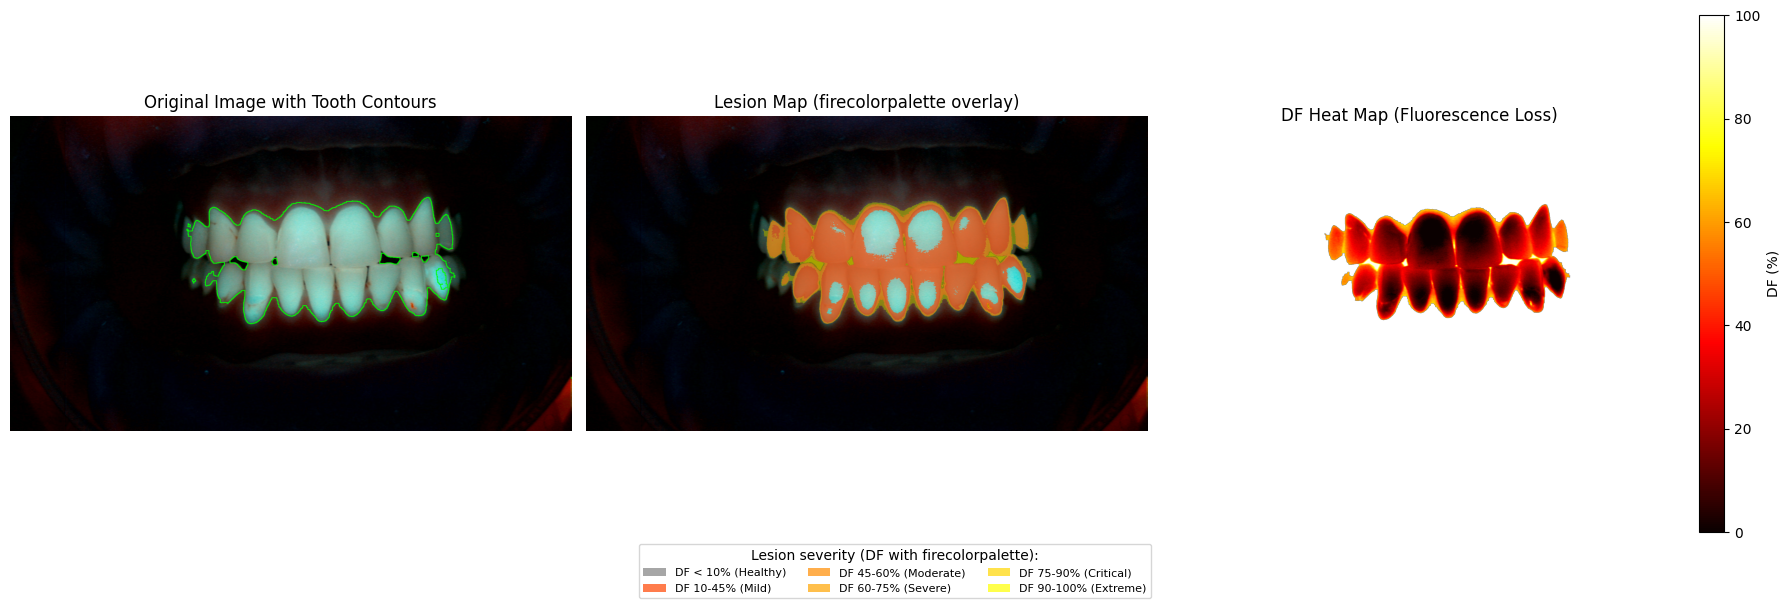


QLF ANALYSIS RESULTS

--- Summary ---
Total lesions: 1
Mean DF (%): 33.0
Total area (px): 221816
Total DQ: 7314839.2
Healthy area (px): 54453.0
Enamel affected (%): 80.29

--- Lesion details ---
 id  DF (%)  Area (px)  DQ (DF*px) Severity
  1    33.0     221816   7314839.2     Mild

--- Treatment recommendations ---
Lesion #1 (DF=33.0%): Remineralization therapy



In [4]:
# ==============================================================================
# 6. ПРИМЕР ИСПОЛЬЗОВАНИЯ
# ==============================================================================

if __name__ == "__main__":
    # ================================================================
    # УКАЖИТЕ ПУТИ К ВАШИМ ИЗОБРАЖЕНИЯМ (ЛЮБОЕ КОЛИЧЕСТВО)
    # ================================================================
    
    image_paths = [
        "uploads/20260228_113710_mihn.jpg",

    ]
    
    
    # Запуск анализа всех изображений
    analyze_multiple_images(image_paths)